# 📊 EDA — Análise Exploratória das Redações do ENEM

Este notebook explora o dataset Essay-BR para entender a distribuição
de notas, características textuais e correlações entre features e competências.

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
%matplotlib inline

In [2]:
# Carregar dados processados
df = pd.read_csv('../data/processed/essays_processed.csv')
print(f'Total de redações: {len(df)}')
df.head()

Total de redações: 770


,id,id_prompt,essay,essay_year,supporting_text,prompt,reference,split,C1,C2,C3,C4,C5,total,essay_clean,C1_norm,C2_norm,C3_norm,C4_norm,C5_norm
0,8.html,posse-de-armas-mais-seguranca-ou-mais-perigo,O Brasil vive uma epidemia de homicídios nas ú...,2019,A opinião do presidente\n“O governo à época bu...,"No dia 15 do mês de janeiro passado, o preside...",grader_a,train,160,120,120,120,80,600,O Brasil vive uma epidemia de homicídios nas ú...,0.8,0.6,0.6,0.6,0.4
1,0.html,a-ciencia-na-era-da-pos-verdade,"De acordo com a poesia do poeta maranhense, na...",2019,"Pós-verdade\nEm 2016, o dicionário de Oxford e...","Os governos, os grandes veículos de comunicaçã...",grader_b,train,80,120,80,120,120,520,"De acordo com a poesia do poeta maranhense, na...",0.4,0.6,0.4,0.6,0.6
2,14.html,preservacao-da-amazonia-desafio-brasileiro-ou-...,A floresta amazônica é maior floresta equatori...,2019,"Status internacional\nO presidente da França, ...","No final de agosto passado, as queimadas na fl...",grader_a,train,120,120,120,120,120,600,A floresta amazônica é maior floresta equatori...,0.6,0.6,0.6,0.6,0.6
3,2.html,a-ciencia-na-era-da-pos-verdade,Durante toda a evolução do planeta em que habi...,2019,"Pós-verdade\nEm 2016, o dicionário de Oxford e...","Os governos, os grandes veículos de comunicaçã...",grader_b,train,120,120,160,160,120,680,Durante toda a evolução do planeta em que habi...,0.6,0.6,0.8,0.8,0.6
4,1.html,universidade-em-crise-quem-paga-a-conta,A crise econômica sem precedentes pela qual o ...,2019,"Quem pode deve pagar\nO governador da Bahia, R...",Após as manifestações contra o contingenciamen...,grader_b,train,160,120,160,160,80,680,A crise econômica sem precedentes pela qual o ...,0.8,0.6,0.8,0.8,0.4


In [3]:
df.describe()

,essay_year,C1,C2,C3,C4,C5,total,C1_norm,C2_norm,C3_norm,C4_norm,C5_norm
count,770.000000,770.000000,770.000000,770.000000,770.000000,770.000000,770.000000,770.000000,770.000000,770.000000,770.000000,770.000000
mean,2018.810390,141.142857,122.181818,118.493506,135.220779,78.233766,595.272727,0.705714,0.610909,0.592468,0.676104,0.391169
std,0.913927,33.328453,50.623352,47.838214,31.651805,59.306766,163.627573,0.166642,0.253117,0.239191,0.158259,0.296534
min,2015.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2019.000000,120.000000,120.000000,80.000000,120.000000,40.000000,480.000000,0.600000,0.600000,0.400000,0.600000,0.200000
50%,2019.000000,160.000000,120.000000,120.000000,120.000000,80.000000,600.000000,0.800000,0.600000,0.600000,0.600000,0.400000
75%,2019.000000,160.000000,160.000000,160.000000,160.000000,120.000000,720.000000,0.800000,0.800000,0.800000,0.800000,0.600000
max,2020.000000,200.000000,200.000000,200.000000,200.000000,200.000000,1000.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## Distribuição de Notas por Competência

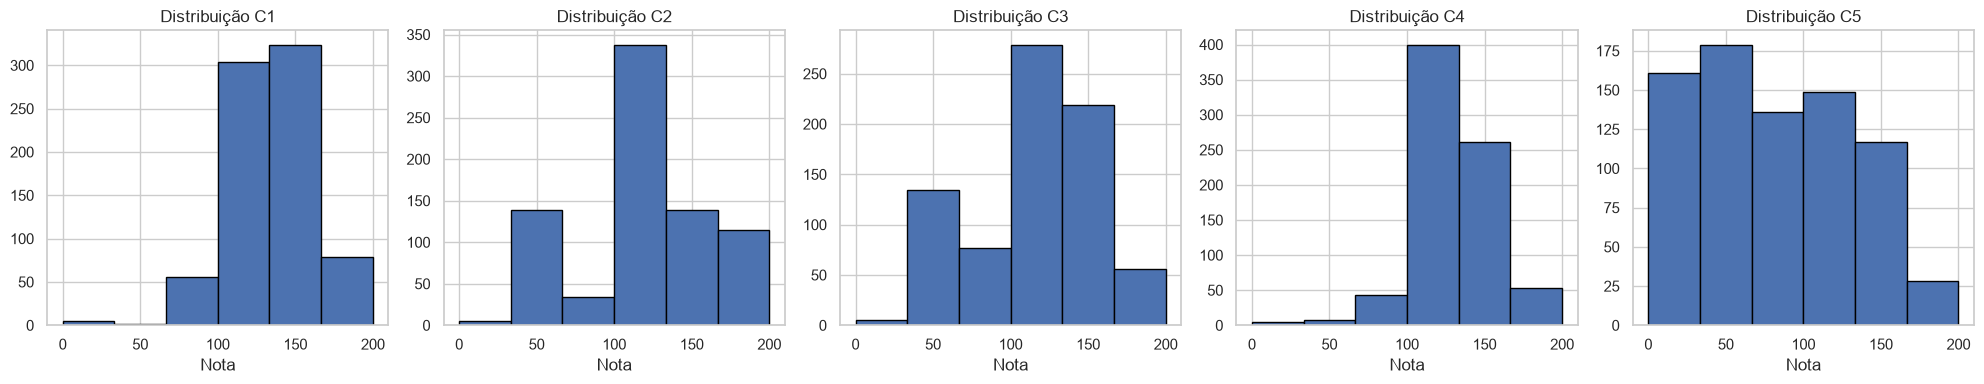

In [4]:
comp_cols = [c for c in df.columns if c in ['C1', 'C2', 'C3', 'C4', 'C5']]

if comp_cols:
    fig, axes = plt.subplots(1, len(comp_cols), figsize=(4*len(comp_cols), 4))
    if len(comp_cols) == 1:
        axes = [axes]
    for ax, col in zip(axes, comp_cols):
        df[col].hist(bins=6, ax=ax, edgecolor='black')
        ax.set_title(f'Distribuição {col}')
        ax.set_xlabel('Nota')
    plt.tight_layout()
    plt.show()
else:
    print('Colunas de competência não encontradas.')

## Comprimento das Redações

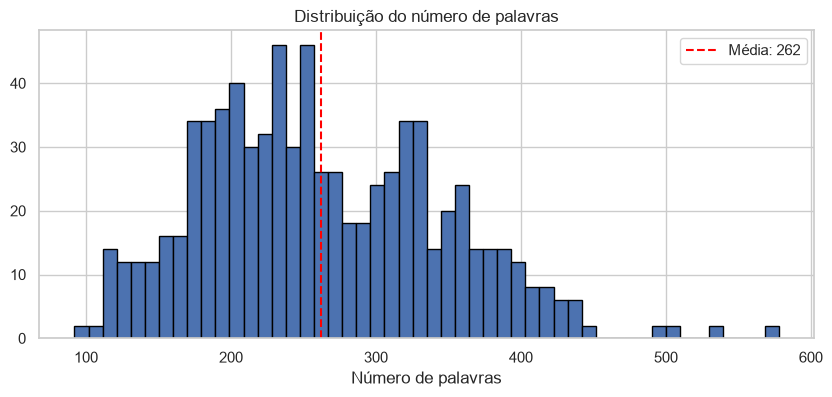

In [5]:
if 'essay_clean' in df.columns:
    df['n_words'] = df['essay_clean'].astype(str).str.split().str.len()
    
    fig, ax = plt.subplots(figsize=(10, 4))
    df['n_words'].hist(bins=50, ax=ax, edgecolor='black')
    ax.set_title('Distribuição do número de palavras')
    ax.set_xlabel('Número de palavras')
    ax.axvline(df['n_words'].mean(), color='red', linestyle='--', label=f'Média: {df["n_words"].mean():.0f}')
    ax.legend()
    plt.show()

In [ ]:
# Análise dos temas das redações
tema_col = 'id_prompt'

temas = (
    df[tema_col]
    .fillna('Tema não informado')
    .value_counts()
    .rename_axis('tema')
    .reset_index(name='quantidade')
)

temas['percentual'] = 100 * temas['quantidade'] / len(df)

print(f"Total de redações: {len(df)}")
print(f"Total de temas: {temas['tema'].nunique()}")
print("\nTema mais frequente:")
print(temas.iloc[0])

display(temas)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=temas,
    x='quantidade',
    y='tema',
    color='steelblue'
)
plt.title('Quantidade de redações por tema')
plt.xlabel('Número de redações')
plt.ylabel('Tema')
plt.tight_layout()
plt.show()

## Correlação entre Features e Notas

In [ ]:
# Carregar dados com features (se disponível)
try:
    df_feat = pd.read_csv('../data/processed/essays_with_features.csv')
    numeric_cols = df_feat.select_dtypes(include=[np.number]).columns
    
    if len(numeric_cols) > 5:
        corr = df_feat[numeric_cols].corr()
        fig, ax = plt.subplots(figsize=(14, 10))
        sns.heatmap(corr, annot=False, cmap='RdBu_r', center=0, ax=ax)
        ax.set_title('Matriz de Correlação')
        plt.tight_layout()
        plt.show()
except FileNotFoundError:
    print('Execute extract_features primeiro.')